In [143]:
import kagglehub
import pandas as pd
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer, PorterStemmer
import string
from nltk.tokenize import word_tokenize
from wordcloud import WordCloud
import matplotlib.pyplot as plt
import re
from wordcloud import STOPWORDS

In [144]:
#variables i will need
lem=WordNetLemmatizer()
port=PorterStemmer()

In [145]:

# Download latest version
df=pd.read_csv("email_spam_indo.csv",usecols=['Kategori','Pesan'])
print(df.shape)
df.head(10)


(2636, 2)


,Kategori,Pesan
0,spam,Secara alami tak tertahankan identitas perusah...
1,spam,Fanny Gunslinger Perdagangan Saham adalah Merr...
2,spam,Rumah -rumah baru yang luar biasa menjadi muda...
3,spam,4 Permintaan Khusus Pencetakan Warna Informasi...
4,spam,"Jangan punya uang, dapatkan CD perangkat lunak..."
5,spam,"Nnews yang hebat halo, selamat datang di medzo..."
6,spam,Berikut ini adalah permainan panas di Investme...
7,spam,Simpan uang Anda beli untuk mendapatkan barang...
8,spam,Tidak Terkirim: Bisnis Berbasis Rumah Untuk Or...
9,spam,Simpan uang Anda beli untuk mendapatkan barang...


In [146]:
#look at length of comments
df[df['Pesan'].str.len()<20]

,Kategori,Pesan
568,spam,. JIF.
1990,ham,FYI
2262,ham,Elena Chilkina Hai
2566,ham,Badai Elana ini


In [147]:
#see summary of length
#plot histogram of length of pesan

In [148]:
# Get the highest value
highest_value = df['Pesan'].str.len().max()
print("Highest Value:", highest_value)

Highest Value: 33531


In [149]:
highest_value = df['Pesan'].str.len().sort_values(ascending=False)
highest_value.head()


2337    33531
536     29757
2559    28295
151     23068
126     19470
Name: Pesan, dtype: int64

In [150]:
ind_stopwords=stopwords.words("indonesian")
stopwords = set(ind_stopwords)

In [151]:
def showCloud(dataframe):
    text = ' '.join(dataframe['Pesan'].astype(str).tolist())

    text = re.sub(r'[^A-Za-z\s]', '', text)

    text = text.lower()
    general_words={'enron','ect','cc','kaminski','vince'}
    banned_words=stopwords.union(general_words)
    text = ' '.join(word for word in text.split() if word not in banned_words)
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text)
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')  
    plt.title("Word Cloud")
    plt.show()

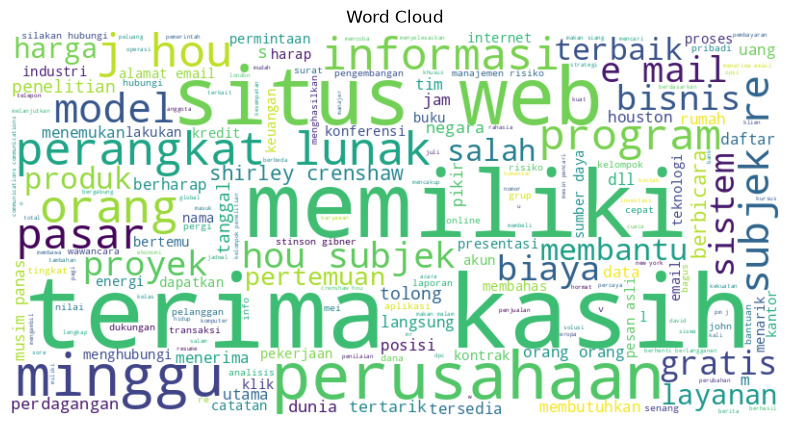

In [152]:
showCloud(df)

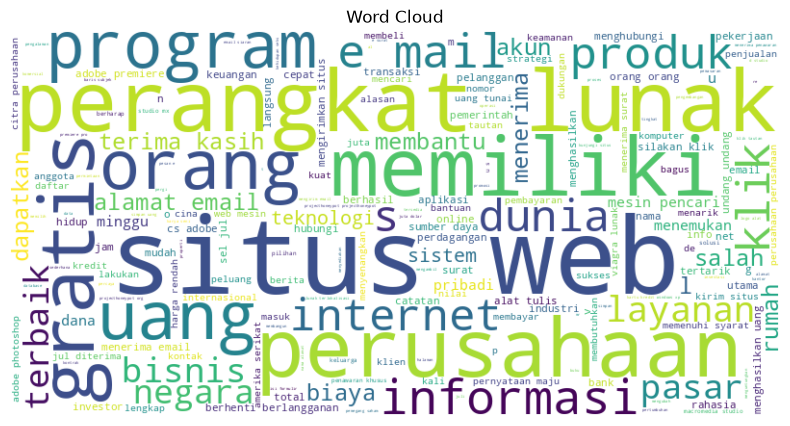

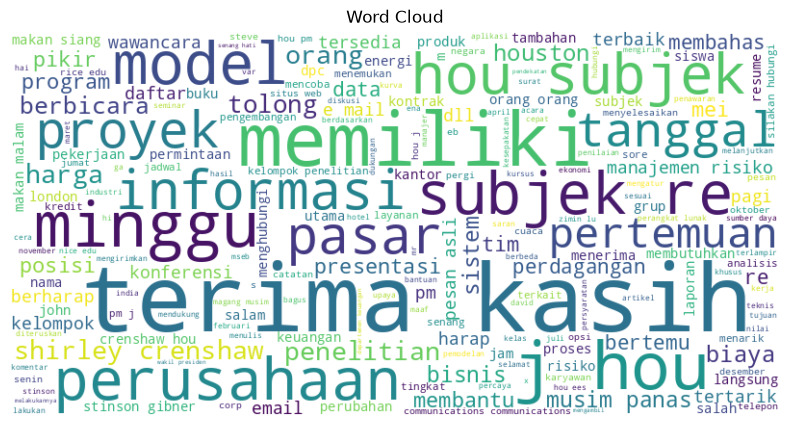

In [153]:
#repeat with spam and nonspam categories
#spam
spam_df = df[df['Kategori']=='spam']
showCloud(spam_df)

ham_df = df[df['Kategori']=='ham']
showCloud(ham_df)

In [154]:
#to do list: remove the name vince j kaminski, enron, shirley crenshaw